In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
from possessions import charger_saison, actions_barca, construire_sequences, zone, NX, NY
from markov import matrice_transition, valeur_zones, valeur_iteration, valeur_actions, N

ev = charger_saison(season_id=27, dossier="../data")
a = actions_barca(ev)
seq = construire_sequences(a)
print(len(seq), "possessions")

3323 possessions


In [2]:
P, C = matrice_transition(seq)

print("Taille de P :", P.shape)
print("Chaque ligne somme à 1 :", np.allclose(P.sum(axis=1), 1))
print("Zones jamais visitées :", (C[:N].sum(axis=1) == 0).sum())

Taille de P : (194, 194)
Chaque ligne somme à 1 : True
Zones jamais visitées : 0


In [3]:
V = valeur_zones(P)
V_iter, k = valeur_iteration(P)

print(f"Itération : convergence en {k} itérations")
print(f"Écart max entre les deux méthodes : {np.abs(V - V_iter).max():.1e}")
np.save("../data/V_1516.npy", V)

Itération : convergence en 195 itérations
Écart max entre les deux méthodes : 9.5e-10


In [4]:
for nom, x, y in [("Rond central", 60, 40), ("Point de penalty", 108, 40),
                  ("Devant le but (6 m)", 116, 40), ("Coin offensif", 119, 1)]:
    z = zone(x, y)
    print(f"{nom:22s} zone {z:3d} : V = {V[z]:.1%}")

Rond central           zone 102 : V = 2.7%
Point de penalty       zone 174 : V = 23.7%
Devant le but (6 m)    zone 186 : V = 48.1%
Coin offensif          zone 180 : V = 3.2%


In [5]:
depart = [zones[0] for zones in seq.zones]
print(f"V moyenne des zones de départ : {V[depart].mean():.2%}")
print(f"Taux réel de possessions avec but : {(seq.fin == 'but').mean():.2%}")

V moyenne des zones de départ : 2.80%
Taux réel de possessions avec but : 2.80%


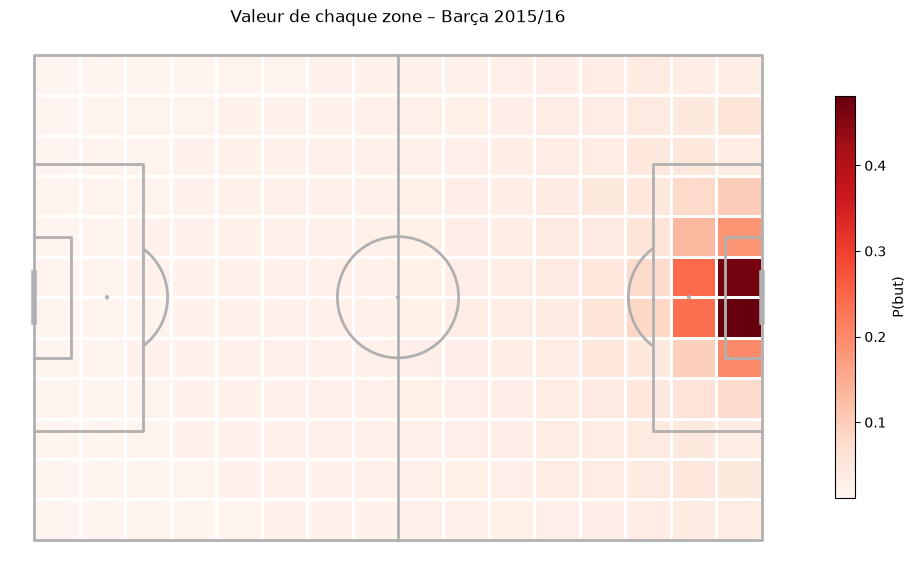

In [6]:
from mplsoccer import Pitch

pitch = Pitch(pitch_type="statsbomb", line_zorder=2)
fig, ax = pitch.draw(figsize=(10, 7))
stats = pitch.bin_statistic([], [], bins=(NX, NY))     # grille vide de la bonne taille
stats["statistic"] = V.reshape(NX, NY).T                # on y met nos valeurs
pcm = pitch.heatmap(stats, ax=ax, cmap="Reds", edgecolors="white")
fig.colorbar(pcm, ax=ax, shrink=0.6, label="P(but)")
ax.set_title("Valeur de chaque zone – Barça 2015/16")
fig.savefig("../figures/xt_barca_1516.png", dpi=150, bbox_inches="tight")

In [7]:
act = valeur_actions(a, seq, V)
mouvements = act[act.type != "Shot"]          # passes et conduites seulement

tableau = mouvements.groupby("player").dV.agg(
    gain=lambda s: s[s > 0].sum(),
    perte=lambda s: s[s < 0].sum(),
    total="sum",
    n="count",
).round(2)
tableau.sort_values("gain", ascending=False).head(8)

,gain,perte,total,n
player,,,,
Neymar da Silva Santos Junior,28.60,-30.36,-1.76,3844
Lionel Andrés Messi Cuccittini,23.25,-21.53,1.72,3834
Luis Alberto Suárez Díaz,15.26,-24.82,-9.56,1864
Daniel Alves da Silva,12.44,-8.79,3.65,3226
Andrés Iniesta Luján,12.25,-11.47,0.78,3477
Jordi Alba Ramos,10.84,-10.54,0.30,3602
Ivan Rakitić,7.75,-11.62,-3.87,3201
Javier Alejandro Mascherano,7.33,-4.48,2.85,3633


In [8]:
z_max = V.argmax()                  # indice de la plus grande valeur
i, j = divmod(z_max, NY)            # colonne i et ligne j de la grille
print(f"Zone {z_max} (colonne {i}, ligne {j}) : V = {V[z_max]:.1%}")

Zone 186 (colonne 15, ligne 6) : V = 48.1%


In [9]:
print("Transitions comptées :", int(C[:N].sum()))
z1, z2 = np.unravel_index(C[:N, :N].argmax(), (N, N))
print(f"Transition la plus fréquente : zone {z1} → zone {z2}, {int(C[z1, z2])} fois")

Transitions comptées : 44699
Transition la plus fréquente : zone 131 → zone 131, 129 fois


In [10]:
z = zone(108, 40)
print(f"P(but direct) = {P[z, N]:.1%}")
print(f"P(perte directe) = {P[z, N + 1]:.1%}")
print(f"P(rester dans le jeu) = {P[z, :N].sum():.1%}")

P(but direct) = 18.1%
P(perte directe) = 44.7%
P(rester dans le jeu) = 37.2%


In [11]:
tableau["gain_par_100"] = (tableau.gain / tableau.n * 100).round(2)
tableau[tableau.n > 500].sort_values("gain_par_100", ascending=False).head(5)

,gain,perte,total,n,gain_par_100
player,,,,,
Luis Alberto Suárez Díaz,15.26,-24.82,-9.56,1864,0.82
Neymar da Silva Santos Junior,28.60,-30.36,-1.76,3844,0.74
Lionel Andrés Messi Cuccittini,23.25,-21.53,1.72,3834,0.61
Daniel Alves da Silva,12.44,-8.79,3.65,3226,0.39
Andrés Iniesta Luján,12.25,-11.47,0.78,3477,0.35
